# HU-4

Notebook para trabajar en la Historia de Usuario 4

## Objetivos (EDA)

- Realizar una limpieza básica de datos (como tratar valores nulos, corregir tipos de datos y revisar valores atípicos o anomalías evidentes) para dejar el dataset preparado

- Generar gráficas y visualizaciones claras para entender las distribuciones y el comportamiento general de las variables

- Realizar un reporte final con las conclusiones principales del análisis y las gráficas más importantes

por último, revisar los links del pdf para hacer un EDA lo más completo posible.

In [196]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [197]:
ruta = Path("../src/data/HU-3.csv")
df = pd.read_csv(ruta, index_col = False)
df.head()

,nregistro,nombre,pactivos,labtitular,labcomercializador,cn,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,...,num_excipientes,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Código Nacional,Estado,Precio venta al público con IVA,Precio de referencia,Tratamiento de larga duración,Especial control médico
0,78686,"ALMOTRIPTAN CINFA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorios Cinfa S.A.,Laboratorios Cinfa S.A.,702112,"12,5 mg",COMPRIMIDO,1397652220000,NaN,...,3.0,636,1,14,NaN,NaN,NaN,NaN,NaN,NaN
1,77646,"ALMOTRIPTAN NORMON 12,5 MG COMPRIMIDOS RECUBIE...",ALMOTRIPTAN,Laboratorios Normon S.A.,Laboratorios Normon S.A.,698376,"12,5 mg",COMPRIMIDO,1371536710000,NaN,...,3.0,662,1,13,698376.0,ALTA,19.53,19.53,NO,NO
2,78394,"ALMOTRIPTAN STADA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorio Stada S.L.,Laboratorio Stada S.L.,701248,"12,5 MG",COMPRIMIDO,1390777200000,NaN,...,4.0,650,1,13,701248.0,ALTA,19.53,19.53,NO,NO
3,69576,IBUPROFENO (ARGININA) KERN PHARMA 600 mg GRANU...,IBUPROFENO,Kern Pharma S.L.,Kern Pharma S.L.,660476,600 mg,SOLUCIÓN/SUSPENSIÓN ORAL,1201647600000,NaN,...,5.0,1375,0,12,660476.0,BAJA POR NO COMERCIALIZAR,2.50,2.50,NO,NO
4,77615,IBUPROFENO STADA 600 MG COMPRIMIDOS RECUBIERTO...,IBUPROFENO,Laboratorio Stada S.L.,Laboratorio Stada S.L.,698275,600 mg,COMPRIMIDO,1370901600000,NaN,...,3.0,1238,0,13,698275.0,ALTA,1.97,1.97,NO,NO


## Eliminamos columnas inútiles

In [198]:
list(df.columns)

['nregistro',
 'nombre',
 'pactivos',
 'labtitular',
 'labcomercializador',
 'cn',
 'dosis',
 'forma_farmaceutica_simplificada',
 'estado_aut',
 'estado_rev',
 'vias_administracion',
 'comercializado',
 'requiere_receta',
 'generico',
 'afecta_conduccion',
 'triangulo_negro',
 'medicamento_huerfano',
 'biosimilar',
 'url_html_ficha_tecnica',
 'url_foto_materiales',
 'num_registros_atc',
 'num_principios_activos',
 'num_excipientes',
 'Volumen_Informativo',
 'Complejidad_Desglose',
 'Indicador_Riesgo',
 'Código Nacional',
 'Estado',
 'Precio venta al público con IVA',
 'Precio de referencia',
 'Tratamiento de larga duración',
 'Especial control médico']

In [199]:
columnas_a_eliminar = [
    "cn",
    "Código Nacional", #Ya aparecen en "cn", además tiene muchos nulos
    "url_html_ficha_tecnica",
    "url_foto_materiales"
]
# además, la primera columna, que es un index

In [200]:
df.drop(columnas_a_eliminar, axis = 1, inplace = True)
#df.drop(df.columns[0], axis = 1, inplace = True)

## Gestionamos precios

Parece que las columnas `Precio venta al público con IVA` y `Precio de referencia` son iguales. 

Por ello me imprimo qué filas son distintas en esas dos columnas con `df["Precio venta al público con IVA"] != df["Precio de referencia"]`. Sin embargo, `pandas` identifica dos `nan` como distintos. Para lo que nosotros queremos, que es quedarnos con una sola columna, dos `nan` son iguales.

Por ello filtramos con la condición `condicion_nan`. Quiere decir que al menos una de ellas sea `nan`. Así detectamos qué filas tienen valor en una columna y `nan` en otra.

En conclusión, nos quedamos con la columna `Precio venta al público con IVA`, ya que esta aporta un valor más.

In [201]:
condicion_nan = df["Precio venta al público con IVA"].notna() | df["Precio de referencia"].notna()

In [202]:
df.loc[(df["Precio venta al público con IVA"] != df["Precio de referencia"]) & condicion_nan]

,nregistro,nombre,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,...,num_principios_activos,num_excipientes,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Precio de referencia,Tratamiento de larga duración,Especial control médico
5,61630,IMIGRAN 20 mg SOLUCION PARA PULVERIZACION NASAL.,SUMATRIPTAN,Glaxosmithkline S.A.,Glaxosmithkline S.A.,20 mg sumatriptan,PRODUCTO USO NASAL,891381600000,NaN,VÍA NASAL,...,1,3.0,543,0,5,ALTA,21.4,NaN,NO,NO


In [203]:
df.drop("Precio de referencia", axis = 1, inplace = True)

## Gestionamos filas duplicadas

Primero revisamos si hay medicamentos con el nombre duplicado:
- Si los hay, eliminamos los duplicados por `nregistro`. (Podría haber medicamentos con el mismo nombre pero distinto nregistro, quizás con distintos componentes)
- Si no los hay, eliminamos la columna `nregistro`.

In [204]:
nombres_duplicados = int(df["nombre"].duplicated().sum())
print(f"Hay {nombres_duplicados} medicamentos duplicados")

Hay 0 medicamentos duplicados


Además, hay tantos nombres como filas

In [205]:
len(df["nombre"].unique())==len(df)

True

In [206]:
df.drop("nregistro", axis = 1, inplace = True)
df.head()

,nombre,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,...,num_registros_atc,num_principios_activos,num_excipientes,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Tratamiento de larga duración,Especial control médico
0,"ALMOTRIPTAN CINFA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorios Cinfa S.A.,Laboratorios Cinfa S.A.,"12,5 mg",COMPRIMIDO,1397652220000,NaN,VÍA ORAL,1,...,3,1,3.0,636,1,14,NaN,NaN,NaN,NaN
1,"ALMOTRIPTAN NORMON 12,5 MG COMPRIMIDOS RECUBIE...",ALMOTRIPTAN,Laboratorios Normon S.A.,Laboratorios Normon S.A.,"12,5 mg",COMPRIMIDO,1371536710000,NaN,VÍA ORAL,1,...,3,1,3.0,662,1,13,ALTA,19.53,NO,NO
2,"ALMOTRIPTAN STADA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorio Stada S.L.,Laboratorio Stada S.L.,"12,5 MG",COMPRIMIDO,1390777200000,NaN,VÍA ORAL,1,...,3,1,4.0,650,1,13,ALTA,19.53,NO,NO
3,IBUPROFENO (ARGININA) KERN PHARMA 600 mg GRANU...,IBUPROFENO,Kern Pharma S.L.,Kern Pharma S.L.,600 mg,SOLUCIÓN/SUSPENSIÓN ORAL,1201647600000,NaN,VÍA ORAL,1,...,3,1,5.0,1375,0,12,BAJA POR NO COMERCIALIZAR,2.50,NO,NO
4,IBUPROFENO STADA 600 MG COMPRIMIDOS RECUBIERTO...,IBUPROFENO,Laboratorio Stada S.L.,Laboratorio Stada S.L.,600 mg,COMPRIMIDO,1370901600000,NaN,VÍA ORAL,1,...,3,1,3.0,1238,0,13,ALTA,1.97,NO,NO


## Normalizamos los strings

In [207]:
for nombre_columna in df.columns:
    if df[nombre_columna].dtype == "object":
        df[nombre_columna] = df[nombre_columna].str.strip()

## Gestionamos valores únicos 

Así también vemos que no hay dos valores escritos de forma distinta

In [208]:
df["pactivos"].unique()

<StringArray>
[                 'ALMOTRIPTAN',                   'IBUPROFENO',
                  'SUMATRIPTAN',     'NARATRIPTAN HIDROCLORURO',
      'ELETRIPTAN HIDROBROMURO',         'RIZATRIPTAN BENZOATO',
                  'TOPIRAMATO ',         'METOPROLOL SUCCINATO',
 'CAFEINA, ERGOTAMINA TARTRATO',          'IBUPROFENO ARGININA',
  'METOCLOPRAMIDA HIDROCLORURO',        'SUMATRIPTAN SUCCINATO',
     'PROPRANOLOL HIDROCLORURO']
Length: 13, dtype: str

In [209]:
df["labtitular"].unique()

<StringArray>
[                          'Laboratorios Cinfa S.A.',
                          'Laboratorios Normon S.A.',
                            'Laboratorio Stada S.L.',
                                  'Kern Pharma S.L.',
                              'Glaxosmithkline S.A.',
                                        'Glaxo S.A.',
                        'Viatris Healthcare Limited',
                        'Glenmark Arzneimittel Gmbh',
      'Tecnimede España Industria Farmaceutica S.A.',
                                     'Almirall S.A.',
 'Recordati Industria Chimica E Farmaceutica S.P.A.',
                                 'Amdipharm Limited',
                               'Arafarma Group S.A.',
                                   'Mabo Farma S.A.',
                          'Towa Pharmaceutical S.A.',
         'Industria Quimica Y Farmaceutica Vir S.A.',
                     'Laboratorios Bluepharma, S.L.',
              'Hc Clover Productos Y Servicios S.L.',
              

In [210]:
df["labcomercializador"].unique()

<StringArray>
[                     'Laboratorios Cinfa S.A.',
                     'Laboratorios Normon S.A.',
                       'Laboratorio Stada S.L.',
                             'Kern Pharma S.L.',
                         'Glaxosmithkline S.A.',
                                   'Glaxo S.A.',
               'Viatris Pharmaceuticals S.L.U.',
                  'Glenmark Farmaceutica S.L.U',
 'Tecnimede España Industria Farmaceutica S.A.',
                                'Almirall S.A.',
                         'Casen Recordati S.L.',
                   'Advanz Pharma Spain S.L.U.',
                          'Arafarma Group S.A.',
                              'Mabo Farma S.A.',
                     'Towa Pharmaceutical S.A.',
    'Industria Quimica Y Farmaceutica Vir S.A.',
                'Laboratorios Bluepharma, S.L.',
         'Hc Clover Productos Y Servicios S.L.',
         'Laboratorios Farmaceuticos Rovi S.A.',
                   'Laboratorios Combix S.L.U.',
      

In [211]:
df["forma_farmaceutica_simplificada"].unique()

<StringArray>
[                       'COMPRIMIDO',          'SOLUCIÓN/SUSPENSIÓN ORAL',
                'PRODUCTO USO NASAL', 'COMPRIMIDO BUCODISPERSABLE/LIOTAB',
  'COMPRIMIDO LIBERACION MODIFICADA',                           'CAPSULA',
                        'INYECTABLE']
Length: 7, dtype: str

In [212]:
df["forma_farmaceutica_simplificada"] = df["forma_farmaceutica_simplificada"].replace("SOLUCIÓN/SUSPENSIÓN ORAL", "SOLUCIÓN")
df["forma_farmaceutica_simplificada"] = df["forma_farmaceutica_simplificada"].replace("COMPRIMIDO BUCODISPERSABLE/LIOTAB", "COMPRIMIDO BUCODISPERSABLE")
df["forma_farmaceutica_simplificada"].unique()

<StringArray>
[                      'COMPRIMIDO',                         'SOLUCIÓN',
               'PRODUCTO USO NASAL',       'COMPRIMIDO BUCODISPERSABLE',
 'COMPRIMIDO LIBERACION MODIFICADA',                          'CAPSULA',
                       'INYECTABLE']
Length: 7, dtype: str

In [213]:
df["vias_administracion"].unique()

<StringArray>
['VÍA ORAL', 'VÍA NASAL', 'VÍA INTRAMUSCULAR']
Length: 3, dtype: str

In [214]:
df["vias_administracion"] = df["vias_administracion"].replace("VÍA INTRAMUSCULAR ,VÍA INTRAVENOSA", "VÍA INTRAVENOSA")
df["vias_administracion"].unique()

<StringArray>
['VÍA ORAL', 'VÍA NASAL', 'VÍA INTRAMUSCULAR']
Length: 3, dtype: str

In [215]:
df["comercializado"].unique()

array([1, 0])

In [216]:
df["requiere_receta"].unique()

array([1])

Si `.unique()` solo devuelve un valor, es que todos son iguales en esa columna, así que podríamos eliminarla. En este caso, todos requieren receta. No obstante, habría que indicar que "todos requieren receta".

In [217]:
df = df.drop("requiere_receta", axis=1)

In [218]:
df.columns

Index(['nombre', 'pactivos', 'labtitular', 'labcomercializador', 'dosis',
       'forma_farmaceutica_simplificada', 'estado_aut', 'estado_rev',
       'vias_administracion', 'comercializado', 'generico',
       'afecta_conduccion', 'triangulo_negro', 'medicamento_huerfano',
       'biosimilar', 'num_registros_atc', 'num_principios_activos',
       'num_excipientes', 'Volumen_Informativo', 'Complejidad_Desglose',
       'Indicador_Riesgo', 'Estado', 'Precio venta al público con IVA',
       'Tratamiento de larga duración', 'Especial control médico'],
      dtype='str')

In [219]:
df["generico"].unique(), df["afecta_conduccion"].unique()

(array([ True, False]), array([1, 0]))

In [220]:
df["triangulo_negro"].unique(), df["medicamento_huerfano"].unique(), df["biosimilar"].unique(), df["num_registros_atc"].unique(), df["num_excipientes"].unique()

(array([0]),
 array([0]),
 array([False]),
 array([3]),
 array([ 3.,  4.,  5.,  2.,  1., nan,  6.]))

In [221]:
df = df.drop(["triangulo_negro", "medicamento_huerfano", "biosimilar", "num_registros_atc", "num_excipientes"], axis=1)

In [222]:
df["num_principios_activos"].unique()

array([1, 2])

In [223]:
df["Volumen_Informativo"].unique()

array([ 636,  662,  650, 1375, 1238,  543,  510,  657,  684,  638, 1688,
       1314,  648,  642,  449,  369, 1180, 1390, 1070, 1093, 1483, 1423,
       1495, 1443, 1506, 1332, 1305, 1205, 1484, 1451,  438,  436,  538,
        550,  443,  711,  640,  591,  610,  721, 1534, 1680, 1650, 1776,
       1774])

In [224]:
df["Complejidad_Desglose"].unique(), df["Indicador_Riesgo"].unique()

(array([1, 0, 6, 3, 2, 5, 4]),
 array([14, 13, 12,  5, 10,  9,  4,  2,  8, 15, 16,  7, 11]))

In [225]:
df["Estado"].unique()

<StringArray>
[                          nan,                        'ALTA',
   'BAJA POR NO COMERCIALIZAR',                'BAJA GENERAL',
 'SUSPENSION TEMPORAL GENERAL']
Length: 5, dtype: str

In [226]:
df["Precio venta al público con IVA"].unique()

array([  nan, 19.53,  2.5 ,  1.97, 21.4 ,  8.8 , 17.59, 26.4 , 36.62,
       73.25,  9.16, 18.31,  0.17,  2.06,  1.89,  2.  ,  1.9 ,  2.58,
       12.18,  1.42,  1.98])

In [227]:
df["Tratamiento de larga duración"].unique(), df["Especial control médico"].unique()

(<StringArray>
 [nan, 'NO', 'SI']
 Length: 3, dtype: str,
 <StringArray>
 [nan, 'NO']
 Length: 2, dtype: str)

In [228]:
df.head()

,nombre,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,generico,afecta_conduccion,num_principios_activos,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Tratamiento de larga duración,Especial control médico
0,"ALMOTRIPTAN CINFA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorios Cinfa S.A.,Laboratorios Cinfa S.A.,"12,5 mg",COMPRIMIDO,1397652220000,NaN,VÍA ORAL,1,True,1,1,636,1,14,NaN,NaN,NaN,NaN
1,"ALMOTRIPTAN NORMON 12,5 MG COMPRIMIDOS RECUBIE...",ALMOTRIPTAN,Laboratorios Normon S.A.,Laboratorios Normon S.A.,"12,5 mg",COMPRIMIDO,1371536710000,NaN,VÍA ORAL,1,True,1,1,662,1,13,ALTA,19.53,NO,NO
2,"ALMOTRIPTAN STADA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorio Stada S.L.,Laboratorio Stada S.L.,"12,5 MG",COMPRIMIDO,1390777200000,NaN,VÍA ORAL,1,True,1,1,650,1,13,ALTA,19.53,NO,NO
3,IBUPROFENO (ARGININA) KERN PHARMA 600 mg GRANU...,IBUPROFENO,Kern Pharma S.L.,Kern Pharma S.L.,600 mg,SOLUCIÓN,1201647600000,NaN,VÍA ORAL,1,True,0,1,1375,0,12,BAJA POR NO COMERCIALIZAR,2.50,NO,NO
4,IBUPROFENO STADA 600 MG COMPRIMIDOS RECUBIERTO...,IBUPROFENO,Laboratorio Stada S.L.,Laboratorio Stada S.L.,600 mg,COMPRIMIDO,1370901600000,NaN,VÍA ORAL,1,True,0,1,1238,0,13,ALTA,1.97,NO,NO


## Gestionamos valores nulos

Queremos mirar qué columnas tienen valores nulos.

In [229]:
df.isna().sum()

nombre                              0
pactivos                            0
labtitular                          0
labcomercializador                  0
dosis                               0
forma_farmaceutica_simplificada     0
estado_aut                          0
estado_rev                         51
vias_administracion                 0
comercializado                      0
generico                            0
afecta_conduccion                   0
num_principios_activos              0
Volumen_Informativo                 0
Complejidad_Desglose                0
Indicador_Riesgo                    0
Estado                             22
Precio venta al público con IVA    22
Tratamiento de larga duración      22
Especial control médico            22
dtype: int64

### `Tratamiento de larga ducación`

Es razonable pensar que si un tratamiento es de larga duración, estaría indicado. En este caso, es más grave que sí sea de larga duración y no indicarlo, que no sea de larga duración y no indicarlo.

Luego, suponemos que los nulos no son de larga duración.

In [230]:
df["Tratamiento de larga duración"].unique()

<StringArray>
[nan, 'NO', 'SI']
Length: 3, dtype: str

In [231]:
df["Tratamiento de larga duración"] = df["Tratamiento de larga duración"].replace(pd.NA, 'NO')
df["Tratamiento de larga duración"].unique()

<StringArray>
['NO', 'SI']
Length: 2, dtype: str

### `Especial control médico`.

En esta columna tenemos más razón para sustituir todos los `nan` por NO. También podemos eliminar la columna. 

No hay ningún medicamento de especial control médico, y si lo hubiera, sería un grave error por parte de la farmacéutica no indicarlo. En un caso real, podríamos considerar contactar con las farmaceuticas.

In [232]:
df["Especial control médico"].unique()

<StringArray>
[nan, 'NO']
Length: 2, dtype: str

In [233]:
df = df.drop("Especial control médico", axis=1)

## `Precio venta al público con IVA`

### `Estado`

Veamos si existe relación entre el precio y `Estado`, porque tienen exactamente el mismo número de nulos, 22.

In [234]:
df.isna().sum()

nombre                              0
pactivos                            0
labtitular                          0
labcomercializador                  0
dosis                               0
forma_farmaceutica_simplificada     0
estado_aut                          0
estado_rev                         51
vias_administracion                 0
comercializado                      0
generico                            0
afecta_conduccion                   0
num_principios_activos              0
Volumen_Informativo                 0
Complejidad_Desglose                0
Indicador_Riesgo                    0
Estado                             22
Precio venta al público con IVA    22
Tratamiento de larga duración       0
dtype: int64

In [235]:
df_nulos = df[["labcomercializador","comercializado","afecta_conduccion", "Precio venta al público con IVA", "Tratamiento de larga duración"]]

ruta_nulos = Path("../src/data/.tmp/df_nulos.csv")
ruta_nulos.parent.mkdir(parents=True, exist_ok=True)
df_nulos.to_csv(ruta_nulos, index=False)

In [236]:
df_nulos_conduccion = df[["labcomercializador","comercializado", "afecta_conduccion", "Precio venta al público con IVA"]]

ruta_nulos_conduccion = Path("../src/data/.tmp/df_nulos_conduccion.csv")
ruta_nulos_conduccion.parent.mkdir(parents=True, exist_ok=True)
df_nulos_conduccion.to_csv(ruta_nulos_conduccion, index=False)

In [237]:
nulos_conduccion = ((df["Precio venta al público con IVA"].isna()) & (df["afecta_conduccion"]==1)).sum()
nulos_totales = df["Precio venta al público con IVA"].isna().sum()
print(f"De {nulos_totales} valores nulos, {nulos_conduccion} afectan a la conducción. Proporción: {nulos_conduccion/nulos_totales}")

De 22 valores nulos, 16 afectan a la conducción. Proporción: 0.7272727272727273


In [238]:
no_nulos_conduccion = ((~df["Precio venta al público con IVA"].isna()) & (df["afecta_conduccion"]==1)).sum()
no_nulos_totales = 70 - df["Precio venta al público con IVA"].isna().sum()
print(f"De {no_nulos_totales} valores no nulos, {no_nulos_conduccion} afectan a la conducción. Proporción: {no_nulos_conduccion/no_nulos_totales}")

De 48 valores no nulos, 30 afectan a la conducción. Proporción: 0.625


La diferencia entre las proporciones no es significativa como para atribuir a la conducción la causa de ser nulos.

### `comercializado`

Podríamos pensar que la respuesta a los 22 valores nulos está en si un medicamento está comercializado o no. Sin embargo, no existe ninguna relación entre ambos. Puedes estar comercializado y no tener precio, y puedes no estar comercializado y tener precio, tal y como muestran los siguientes ejemplos:

In [239]:
df.iloc[24]["comercializado"], df.iloc[24]["Precio venta al público con IVA"]

(np.int64(1), np.float64(nan))

In [240]:
df.iloc[25]["comercializado"], df.iloc[25]["Precio venta al público con IVA"]

(np.int64(0), np.float64(36.62))

In [241]:
df_nulos_precio = df[["comercializado", "Precio venta al público con IVA"]]

ruta_nulos_precio = Path("../src/data/.tmp/df_nulos_precio.csv")
ruta_nulos_precio.parent.mkdir(parents=True, exist_ok=True)
df_nulos_precio.to_csv(ruta_nulos_precio, index=False)

In [242]:
sin_precio = len(df.loc[df["Precio venta al público con IVA"].isna()])
com_sin_precio = len(df.loc[(df["comercializado"]==1) & (df["Precio venta al público con IVA"].isna())])
no_com_sin_precio = len(df.loc[(df["comercializado"]==0) & (df["Precio venta al público con IVA"].isna())])

In [243]:
print(f"De {sin_precio} medicamentos sin precio (nulos), {com_sin_precio} están comercializados y {no_com_sin_precio} no lo están.")

De 22 medicamentos sin precio (nulos), 10 están comercializados y 12 no lo están.


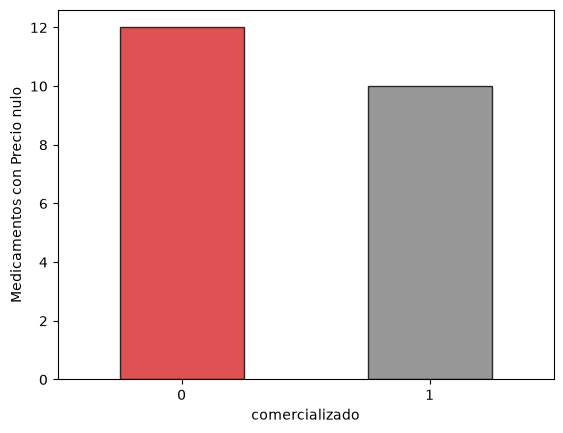

In [244]:
conteo_nulos = df.loc[df["Precio venta al público con IVA"].isna(), "comercializado"].value_counts()

conteo_nulos.plot(
    kind="bar", 
    color=["tab:red", "tab:gray"],
    edgecolor="black",
    alpha=0.8
)

plt.ylabel("Medicamentos con Precio nulo")
plt.xticks(rotation=0)

plt.show()

In [245]:
df["Precio venta al público con IVA"].describe()

count    48.000000
mean     16.357500
std      20.206262
min       0.170000
25%       2.060000
50%       8.800000
75%      19.530000
max      73.250000
Name: Precio venta al público con IVA, dtype: float64

## ¿Qué nos dice lo anterior?

Todo el `describe` lo hace con los medicamentos cuyo precio es no nulo.

- `count` = 48. Hay 48 medicamentos no nulos.

- `mean` = 16.3575. La media de los precios no nulos.

- `std` = 20.206262 es la desviación típica. (Lo siguiente no mejora nada el EDA, pero me pareció interesante)
    - En una __normal__, sabemos que, para un punto, la probabilidad de encontrarse en $[\mu - \sigma, \mu + \sigma]$ es 0.68.
    - La probabilidad de encontrarse en $[\mu - 2\sigma, \mu + 2\sigma]$ en una normal es 0.95
    - Pero como no sabemos si nuestros datos siguen una distribución normal, la desigualdad de Chebyshev nos dice que, si $X$ es una variable aleatoria $(\mu, \sigma \neq 0)$, entonces $\forall k > 0$ se tiene $$P(|X - \mu| \geq k \sigma) \leq \frac{1}{k^2}$$ Si tomamos $k=2$, entonces la probabilidad de estar dentro de $[\mu - 2\sigma, \mu + 2\sigma]$ es al menos 0.75.

- `min`: el precio mínimo es 17 céntimos

- `max`: el precio máximo es 73.25€

- El 75% de los medicamentos están por debajo de 19.53€

<p align="center">
<img src="https://storage.ghost.io/c/a0/9c/a09ce472-4800-46e6-92f1-9d3827e5d8b6/content/images/2021/11/normal_dist-1.png" width="700" alt="Desviación típica en una normal">
</p>

In [246]:
# De aquí solo modificar `proporcion`
proporcion = 0.91
porcentaje = proporcion * 100
quantil = df["Precio venta al público con IVA"].quantile(proporcion)
print(f"El {porcentaje}% de los datos cuesta, como mucho, {float(quantil)}€")

El 91.0% de los datos cuesta, como mucho, 36.62€


Probablemente haya outliers.

Solo hay 4 medicamentos que cuestan más de 37€. En particular, 73.25€. Los que están cerca de 40€ no los consideramos outliers.

In [247]:
df.loc[df["Precio venta al público con IVA"] > 37]

,nombre,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,generico,afecta_conduccion,num_principios_activos,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Tratamiento de larga duración
14,TOPIRAMATO STADA 200 mg COMPRIMIDOS RECUBIERTO...,TOPIRAMATO,Laboratorio Stada S.L.,Laboratorio Stada S.L.,200 mg,COMPRIMIDO,1173826800000,NaN,VÍA ORAL,1,True,1,1,1688,3,14,ALTA,73.25,NO
18,TOPIRAMATO TECNIGEN 200 mg COMPRIMIDOS RECUBIE...,TOPIRAMATO,Tecnimede España Industria Farmaceutica S.A.,Tecnimede España Industria Farmaceutica S.A.,200 mg,COMPRIMIDO,1236553200000,NaN,VÍA ORAL,1,True,1,1,1314,3,9,ALTA,73.25,NO
26,FAGODOL 200 mg COMPRIMIDOS RECUBIERTOS CON PEL...,TOPIRAMATO,Arafarma Group S.A.,Arafarma Group S.A.,200 mg,COMPRIMIDO,1182290400000,1.675946e+12,VÍA ORAL,0,True,1,1,1180,0,8,BAJA GENERAL,73.25,NO
67,TOPIRAMATO TEVA 200 mg COMPRIMIDOS RECUBIERTOS...,TOPIRAMATO,Teva Pharma S.L.U.,Teva Pharma S.L.U.,200 mg,COMPRIMIDO,1181512800000,1.748966e+12,VÍA ORAL,0,True,1,1,1776,4,14,BAJA GENERAL,73.25,NO


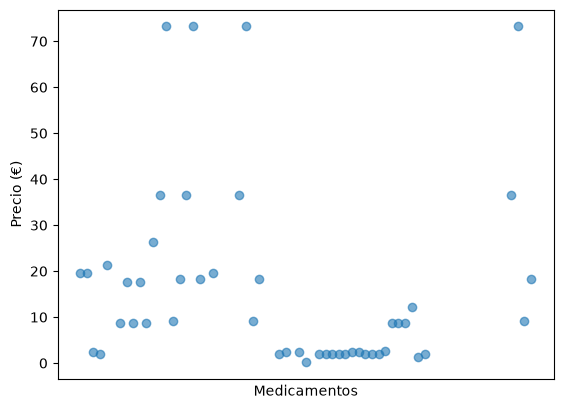

In [248]:
df.plot(
    x="nombre", 
    y="Precio venta al público con IVA", 
    kind="line", 
    marker="o", 
    linestyle="", 
    legend=False,
    alpha=0.6 
)

plt.xticks([]) 
plt.xlabel("Medicamentos")
plt.ylabel("Precio (€)")

plt.show()

Los 4 outliers son de distintos laboratorios. Podría ser debido al principio activo TOPIRAMATO, pero muchos más lo tienen. Con respecto a volumen informativo, están en valores aceptables (`df["Volumen_Informativo"].describe()`).

In [249]:
#df["Volumen_Informativo"].describe()

Podríamos ver que, de las filas con valores nulos, si pertenecen al mismo `labcomercializador` que alguno de los de 73€. Solo hay uno. Los siguientes están marcados con #. Luego, la respuesta de los nulos no está en `labcomercializador`.

In [250]:
df.loc[(df["Precio venta al público con IVA"].isna()) & (df["labcomercializador"] == 'Tecnimede España Industria Farmaceutica S.A.')]

,nombre,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,generico,afecta_conduccion,num_principios_activos,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Tratamiento de larga duración
65,TOPIRAMATO TECNIGEN 25 mg COMPRIMIDOS RECUBIER...,TOPIRAMATO,Tecnimede España Industria Farmaceutica S.A.,Tecnimede España Industria Farmaceutica S.A.,25 mg,COMPRIMIDO,1236553200000,1.709651e+12,VÍA ORAL,0,True,1,1,1314,3,9,NaN,NaN,NO


In [251]:
#df.loc[(df["Precio venta al público con IVA"].isna()) & (df["labcomercializador"] == 'Laboratorio Stada S.L.')]

In [252]:
#df.loc[(df["Precio venta al público con IVA"].isna()) & (df["labcomercializador"] == 'Arafarma Group S.A.')]

In [253]:
#df.loc[(df["Precio venta al público con IVA"].isna()) & (df["labcomercializador"] == 'Teva Pharma S.L.U.')]

## `df_sin_outliers`

Vamos a crear un `df_sin_outliers`, eliminando los outliers para obtener un nuevo `.describe` y dar valores de precio a los nulos.

In [254]:
df_sin_outliers = df.copy()
df_sin_outliers = df_sin_outliers.loc[~(df["Precio venta al público con IVA"] > 37)]
len(df_sin_outliers)

66

Antes:
```bash
count    48.000000
mean     16.357500
std      20.206262
min       0.170000
25%       2.060000
50%       8.800000
75%      19.530000
max      73.250000
Name: Precio venta al público con IVA, dtype: float64
```

In [255]:
float(df["Precio venta al público con IVA"].min())

0.17

Ahora:

In [256]:
df_sin_outliers["Precio venta al público con IVA"].describe()

count    44.000000
mean     11.185455
std      10.853938
min       0.170000
25%       2.045000
50%       8.800000
75%      18.310000
max      36.620000
Name: Precio venta al público con IVA, dtype: float64

In [257]:
df["Precio venta al público con IVA"].mode()

0    8.8
Name: Precio venta al público con IVA, dtype: float64

In [258]:
float(df_sin_outliers["Precio venta al público con IVA"].std())

10.853937974579795

In [259]:
media_con_outliers = 16.3575
mediana = 8.8 #es la misma
media_sin_outliers = 11.185455

Vamos a comparar la densidad del dataset original (precios) con dataset imputados por los tres valores definidos arriba. La gráfica que más se asemeje nos indicará el criterio a seguir.

#### Generamos varios dataframes imputados (NaN reemplazados)

Sustituimos los `NaN` por:

- La media de los precios considerando los 4 outliers

- La media de los precios sin considerar los 4 outliers

- La mediana (coincide que es la misma para ambos casos)

- Valores uniformemente aleatorios entre 1er y 3er quantil considerando los 4 outliers

- Valores uniformemente aleatorios entre 1er y 3er quantil sin considerar los 4 outliers

In [260]:
df_media_con_outliers = df.copy()
df_media_con_outliers.loc[df_media_con_outliers["Precio venta al público con IVA"].isna(), "Precio venta al público con IVA"] = media_con_outliers
df_media_con_outliers["Precio venta al público con IVA"]

0     16.3575
1     19.5300
2     19.5300
3      2.5000
4      1.9700
       ...   
65    16.3575
66    36.6200
67    73.2500
68     9.1600
69    18.3100
Name: Precio venta al público con IVA, Length: 70, dtype: float64

In [261]:
df_media_sin_outliers = df.copy()
df_media_sin_outliers.loc[df_media_sin_outliers["Precio venta al público con IVA"].isna(), "Precio venta al público con IVA"] = media_sin_outliers
df_media_sin_outliers["Precio venta al público con IVA"]

0     11.185455
1     19.530000
2     19.530000
3      2.500000
4      1.970000
        ...    
65    11.185455
66    36.620000
67    73.250000
68     9.160000
69    18.310000
Name: Precio venta al público con IVA, Length: 70, dtype: float64

In [262]:
df_mediana = df.copy()
df_mediana.loc[df_mediana["Precio venta al público con IVA"].isna(), "Precio venta al público con IVA"] = mediana
df_mediana["Precio venta al público con IVA"]

0      8.80
1     19.53
2     19.53
3      2.50
4      1.97
      ...  
65     8.80
66    36.62
67    73.25
68     9.16
69    18.31
Name: Precio venta al público con IVA, Length: 70, dtype: float64

¿Cómo funciona `np.where()`?

- Primer argumento: la condición a probar
- Segundo argumento: qué devolver si es cierta
- Tercer argumento: qué devolver si es falsa

Con `size` generamos una lista de números aleatorios, no un único número.

In [263]:
df_random_sin_outliers = df.copy()
columna = "Precio venta al público con IVA"

es_na = df_random_sin_outliers[columna].isna()

df_random_sin_outliers[columna] = np.where(
    es_na,
    np.random.uniform(low=2.045, high=18.31, size=len(df_random_sin_outliers)),
    df_random_sin_outliers[columna],
)

df_random_sin_outliers[columna]

0     11.344530
1     19.530000
2     19.530000
3      2.500000
4      1.970000
        ...    
65     2.329301
66    36.620000
67    73.250000
68     9.160000
69    18.310000
Name: Precio venta al público con IVA, Length: 70, dtype: float64

In [264]:
df_random_con_outliers = df.copy()
columna = "Precio venta al público con IVA"

es_na = df_random_con_outliers[columna].isna()

df_random_con_outliers[columna] = np.where(
    es_na,
    np.random.uniform(low=2.06, high=19.53, size=len(df_random_con_outliers)),
    df_random_con_outliers[columna],
)

df_random_con_outliers[columna]

0     18.249730
1     19.530000
2     19.530000
3      2.500000
4      1.970000
        ...    
65    13.159537
66    36.620000
67    73.250000
68     9.160000
69    18.310000
Name: Precio venta al público con IVA, Length: 70, dtype: float64

In [265]:
df_random_cuantil_90 = df.copy()
columna = "Precio venta al público con IVA"

es_na = df_random_cuantil_90[columna].isna()

df_random_cuantil_90[columna] = np.where(
    es_na,
    np.random.uniform(low=0.17, high=40, size=len(df_random_cuantil_90)),
    df_random_cuantil_90[columna],
)

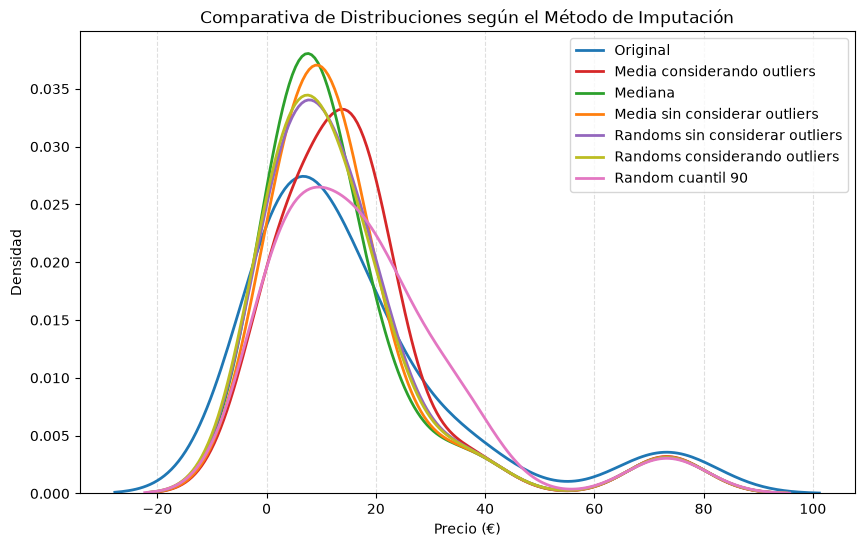

In [266]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=df, 
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:blue", 
    linewidth=2,
    label="Original"
)

sns.kdeplot(
    data=df_media_con_outliers,
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:red", 
    linewidth=2,
    label="Media considerando outliers"
)

sns.kdeplot(
    data=df_mediana,  # Cambia este nombre por el de tu dataframe de la mediana
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:green", 
    linewidth=2,
    label="Mediana"
)

sns.kdeplot(
    data=df_media_sin_outliers,
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:orange", 
    linewidth=2,
    label="Media sin considerar outliers"
)

sns.kdeplot(
    data=df_random_sin_outliers,
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:purple", 
    linewidth=2,
    label="Randoms sin considerar outliers"
)

sns.kdeplot(
    data=df_random_con_outliers,
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:olive", 
    linewidth=2,
    label="Randoms considerando outliers"
)

sns.kdeplot(
    data=df_random_cuantil_90,
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:pink", 
    linewidth=2,
    label="Random cuantil 90"
)

plt.xlabel("Precio (€)")
plt.ylabel("Densidad")
plt.title("Comparativa de Distribuciones según el Método de Imputación")
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.legend() 

plt.show()


Tras correr varias ejecuciones puede observarse que la distribución que más se asemeja es Random [0.17, 40]. Justificación: el cuantil 91 es aprox. 40. 

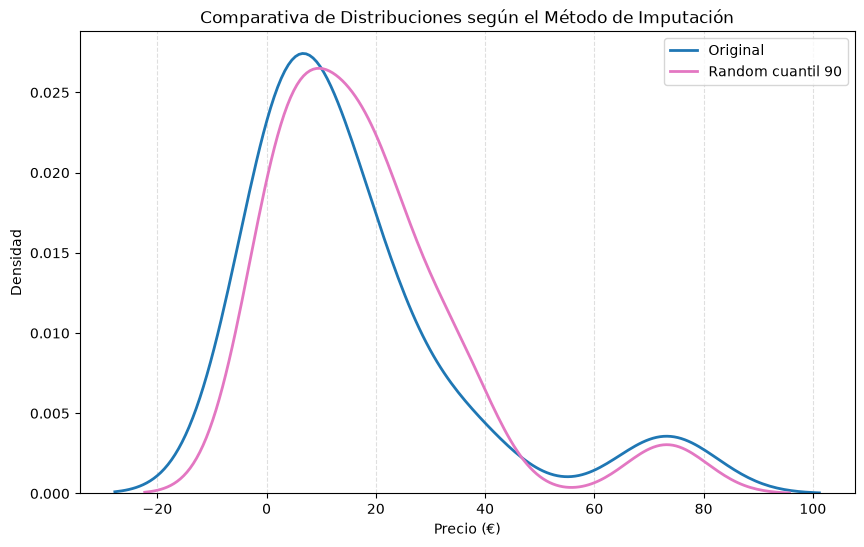

In [267]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=df, 
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:blue", 
    linewidth=2,
    label="Original"
)

sns.kdeplot(
    data=df_random_cuantil_90,
    x="Precio venta al público con IVA", 
    fill=False, 
    color="tab:pink", 
    linewidth=2,
    label="Random cuantil 90"
)

plt.xlabel("Precio (€)")
plt.ylabel("Densidad")
plt.title("Comparativa de Distribuciones según el Método de Imputación")
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.legend() 

plt.show()

In [268]:
df["Precio venta al público con IVA"] = df_random_cuantil_90["Precio venta al público con IVA"].copy()

## `Estado`

In [269]:
list(df["Estado"].mode())[0]

'ALTA'

In [270]:
df["Estado"].value_counts()

Estado
ALTA                           32
BAJA GENERAL                   13
BAJA POR NO COMERCIALIZAR       2
SUSPENSION TEMPORAL GENERAL     1
Name: count, dtype: int64

Sustituimos los nulos por la moda.

In [271]:
df["Estado"]

0                           NaN
1                          ALTA
2                          ALTA
3     BAJA POR NO COMERCIALIZAR
4                          ALTA
                ...            
65                          NaN
66                 BAJA GENERAL
67                 BAJA GENERAL
68                 BAJA GENERAL
69                 BAJA GENERAL
Name: Estado, Length: 70, dtype: str

In [272]:
moda = list(df["Estado"].mode())[0]
df["Estado"] = df["Estado"].replace(pd.NA, 'ALTA')
df["Estado"]

0                          ALTA
1                          ALTA
2                          ALTA
3     BAJA POR NO COMERCIALIZAR
4                          ALTA
                ...            
65                         ALTA
66                 BAJA GENERAL
67                 BAJA GENERAL
68                 BAJA GENERAL
69                 BAJA GENERAL
Name: Estado, Length: 70, dtype: str

In [273]:
df.isna().sum()

nombre                              0
pactivos                            0
labtitular                          0
labcomercializador                  0
dosis                               0
forma_farmaceutica_simplificada     0
estado_aut                          0
estado_rev                         51
vias_administracion                 0
comercializado                      0
generico                            0
afecta_conduccion                   0
num_principios_activos              0
Volumen_Informativo                 0
Complejidad_Desglose                0
Indicador_Riesgo                    0
Estado                              0
Precio venta al público con IVA     0
Tratamiento de larga duración       0
dtype: int64

## Fechas (`estado_aut` y `estado_rev`)

Los datos de las fechas vienen en formato Unix: número de milisegundos desde 1970

Hay que transformarlo a un formato de pandas datetime.

In [274]:
df.head()

,nombre,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,generico,afecta_conduccion,num_principios_activos,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Tratamiento de larga duración
0,"ALMOTRIPTAN CINFA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorios Cinfa S.A.,Laboratorios Cinfa S.A.,"12,5 mg",COMPRIMIDO,1397652220000,NaN,VÍA ORAL,1,True,1,1,636,1,14,ALTA,15.891631,NO
1,"ALMOTRIPTAN NORMON 12,5 MG COMPRIMIDOS RECUBIE...",ALMOTRIPTAN,Laboratorios Normon S.A.,Laboratorios Normon S.A.,"12,5 mg",COMPRIMIDO,1371536710000,NaN,VÍA ORAL,1,True,1,1,662,1,13,ALTA,19.530000,NO
2,"ALMOTRIPTAN STADA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorio Stada S.L.,Laboratorio Stada S.L.,"12,5 MG",COMPRIMIDO,1390777200000,NaN,VÍA ORAL,1,True,1,1,650,1,13,ALTA,19.530000,NO
3,IBUPROFENO (ARGININA) KERN PHARMA 600 mg GRANU...,IBUPROFENO,Kern Pharma S.L.,Kern Pharma S.L.,600 mg,SOLUCIÓN,1201647600000,NaN,VÍA ORAL,1,True,0,1,1375,0,12,BAJA POR NO COMERCIALIZAR,2.500000,NO
4,IBUPROFENO STADA 600 MG COMPRIMIDOS RECUBIERTO...,IBUPROFENO,Laboratorio Stada S.L.,Laboratorio Stada S.L.,600 mg,COMPRIMIDO,1370901600000,NaN,VÍA ORAL,1,True,0,1,1238,0,13,ALTA,1.970000,NO


In [275]:
df["estado_aut"].isna().sum()

np.int64(0)

In [276]:
df["estado_aut"].unique()

array([1397652220000, 1371536710000, 1390777200000, 1201647600000,
       1370901600000,  891381600000,  899244000000,  996098400000,
       1389826800000, 1368396000000, 1173826800000, 1236553200000,
        946422000000, 1371536705000,  953679600000, -491878800000,
       1182290400000, 1394016803000, 1152482400000, 1287007200000,
       1191362400000, 1286229600000, 1243375200000, 1297292400000,
       1466071856000, 1128290400000, 1074121200000, 1307484000000,
       1151445600000, 1100127600000, 1190152800000, 1467324000000,
       -160448400000, -142131600000, 1362697200000, 1366322400000,
       1366376485000, 1176933600000, -123555600000, 1216245600000,
       1177365600000, 1196290800000, 1181512800000])

In [277]:
df["estado_aut"]

0     1397652220000
1     1371536710000
2     1390777200000
3     1201647600000
4     1370901600000
          ...      
65    1236553200000
66    1181512800000
67    1181512800000
68    1181512800000
69    1181512800000
Name: estado_aut, Length: 70, dtype: int64

In [278]:
df["estado_aut"] = pd.to_datetime(df["estado_aut"], unit="ms")
df["estado_aut"]

0    2014-04-16 12:43:40
1    2013-06-18 06:25:10
2    2014-01-26 23:00:00
3    2008-01-29 23:00:00
4    2013-06-10 22:00:00
             ...        
65   2009-03-08 23:00:00
66   2007-06-10 22:00:00
67   2007-06-10 22:00:00
68   2007-06-10 22:00:00
69   2007-06-10 22:00:00
Name: estado_aut, Length: 70, dtype: datetime64[ms]

In [279]:
df["estado_rev"] = pd.to_datetime(df["estado_rev"], unit="ms")
df["estado_rev"]

0                    NaT
1                    NaT
2                    NaT
3                    NaT
4                    NaT
             ...        
65   2024-03-05 15:08:36
66   2025-05-09 12:23:00
67   2025-06-03 15:46:50
68   2025-01-16 13:59:18
69   2025-01-16 13:59:12
Name: estado_rev, Length: 70, dtype: datetime64[ms]

## Nulos `estado_rev`

Si no hay fecha de revisión, diremos que es la misma que la fecha de autorización.

In [280]:
df["estado_rev"] = df["estado_rev"].fillna(df["estado_aut"])

In [281]:
df.head()

,nombre,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,generico,afecta_conduccion,num_principios_activos,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Tratamiento de larga duración
0,"ALMOTRIPTAN CINFA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorios Cinfa S.A.,Laboratorios Cinfa S.A.,"12,5 mg",COMPRIMIDO,2014-04-16 12:43:40,2014-04-16 12:43:40,VÍA ORAL,1,True,1,1,636,1,14,ALTA,15.891631,NO
1,"ALMOTRIPTAN NORMON 12,5 MG COMPRIMIDOS RECUBIE...",ALMOTRIPTAN,Laboratorios Normon S.A.,Laboratorios Normon S.A.,"12,5 mg",COMPRIMIDO,2013-06-18 06:25:10,2013-06-18 06:25:10,VÍA ORAL,1,True,1,1,662,1,13,ALTA,19.530000,NO
2,"ALMOTRIPTAN STADA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorio Stada S.L.,Laboratorio Stada S.L.,"12,5 MG",COMPRIMIDO,2014-01-26 23:00:00,2014-01-26 23:00:00,VÍA ORAL,1,True,1,1,650,1,13,ALTA,19.530000,NO
3,IBUPROFENO (ARGININA) KERN PHARMA 600 mg GRANU...,IBUPROFENO,Kern Pharma S.L.,Kern Pharma S.L.,600 mg,SOLUCIÓN,2008-01-29 23:00:00,2008-01-29 23:00:00,VÍA ORAL,1,True,0,1,1375,0,12,BAJA POR NO COMERCIALIZAR,2.500000,NO
4,IBUPROFENO STADA 600 MG COMPRIMIDOS RECUBIERTO...,IBUPROFENO,Laboratorio Stada S.L.,Laboratorio Stada S.L.,600 mg,COMPRIMIDO,2013-06-10 22:00:00,2013-06-10 22:00:00,VÍA ORAL,1,True,0,1,1238,0,13,ALTA,1.970000,NO


In [282]:
df["estado_aut"].dtype == "datetime64[us]"

False

In [283]:
df.dtypes

nombre                                        str
pactivos                                      str
labtitular                                    str
labcomercializador                            str
dosis                                         str
forma_farmaceutica_simplificada               str
estado_aut                         datetime64[ms]
estado_rev                         datetime64[ms]
vias_administracion                           str
comercializado                              int64
generico                                     bool
afecta_conduccion                           int64
num_principios_activos                      int64
Volumen_Informativo                         int64
Complejidad_Desglose                        int64
Indicador_Riesgo                            int64
Estado                                        str
Precio venta al público con IVA           float64
Tratamiento de larga duración                 str
dtype: object

## Dosis

Pasamos de "100 mg" a "100". También indicamos en el nombre de la columna que las unidades son miligramos.

In [284]:
df["dosis"] = df["dosis"].str.strip().str.split().str[0].str.replace(",", ".").astype(float)
df["dosis"]

0      12.5
1      12.5
2      12.5
3     600.0
4     600.0
      ...  
65     25.0
66    100.0
67    200.0
68     25.0
69     50.0
Name: dosis, Length: 70, dtype: float64

In [285]:
df = df.rename(columns={"dosis": "dosis (mg)"})

In [293]:
df["dosis (mg)"].describe()

count     70.000000
mean     168.650000
std      222.279827
min        1.000000
25%       14.375000
50%       50.000000
75%      200.000000
max      600.000000
Name: dosis (mg), dtype: float64

#### Exportar a excel

In [286]:
ruta_export = Path("../src/data/HU4_EDA.xlsx")
#df.to_excel(ruta_export, index=False)

#### Exportar a csv

In [287]:
ruta_export = Path("../src/data/HU-4.csv")
df.to_csv(ruta_export, index=False)

## Comentarios de Guillermo y Emilio
- Al ser nuestro dataset muy pequeño (70 filas), el EDA es muy importante

- Cualquier cambio en él, influye más que en un dataset de 10_000 filas.

- La decisión de qué hacer con los valores nulos es nuestra. Aquí tenemos 22 de 70 (~31%)

- Poner la media es una mala decisión. El objetivo de HU-5 es clusterizar, y si asignamos la media a todos esos nulos, 
sesgamos el modelo hacia un único cluster (que estaría centrado más o menos en la media)

- Esto provocaría casos como: incluir un ibuprofeno en un cluster cuyo precio es 100€ (no tiene sentido)

- Guillermo sugirió dar valores aleatorios en un rango.

- ¡Ojo! A veces pensamos que los nulos se deben a "falta de información", pero se puede deducir por qué en otras columnas de la tabla. Por ejemplo, los nulos de `precio_de_venta` se deben a que no están comercializados.

- También podría haber algunos nulos (como fechas) que quizás no sean tan importantes

### Forzar AQUÍ un ejemplo de contracts que falle

## Siguiente tarea

- Validar datos

In [288]:
from proyecto_ingenieria_dato.contracts import Medicamento

In [289]:
for index, row in df.iterrows():
    try:
        Medicamento(**row.to_dict())
    except Exception as e:
        raise ValueError(f"Error al validar la fila {index+1}. Error: {e}")

In [290]:
medicamento_base = {
    "nombre": "Medicamento de prueba",
    "pactivos": "Principio activo",
    "labtitular": "Laboratorio titular",
    "labcomercializador": "Laboratorio comercializador",
    "dosis (mg)": 12.5,
    "forma_farmaceutica_simplificada": "COMPRIMIDO",
    "estado_aut": "2024-01-01T00:00:00",
    "estado_rev": "2024-01-01T00:00:00",
    "vias_administracion": "VÍA ORAL",
    "comercializado": 1,
    "generico": 0,
    "afecta_conduccion": 0,
    "num_principios_activos": 1,
    "Volumen_Informativo": 0,
    "Complejidad_Desglose": 0,
    "Indicador_Riesgo": 0,
    "Estado": "ALTA",
    "Precio venta al público con IVA": 10.0,
    "Tratamiento de larga duración": "NO",
}

medicamento_invalido = medicamento_base.copy()
medicamento_invalido["nombre"] = "Medicamento con dosis inválida"
medicamento_invalido["dosis (mg)"] = -1  # Debe ser mayor que 0

df_prueba = pd.DataFrame([medicamento_base, medicamento_invalido])

df_prueba


,nombre,pactivos,labtitular,labcomercializador,dosis (mg),forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,generico,afecta_conduccion,num_principios_activos,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Tratamiento de larga duración
0,Medicamento de prueba,Principio activo,Laboratorio titular,Laboratorio comercializador,12.5,COMPRIMIDO,2024-01-01T00:00:00,2024-01-01T00:00:00,VÍA ORAL,1,0,0,1,0,0,0,ALTA,10.0,NO
1,Medicamento con dosis inválida,Principio activo,Laboratorio titular,Laboratorio comercializador,-1.0,COMPRIMIDO,2024-01-01T00:00:00,2024-01-01T00:00:00,VÍA ORAL,1,0,0,1,0,0,0,ALTA,10.0,NO


In [291]:
for index, row in df_prueba.iterrows():
    try:
        Medicamento(**row.to_dict())
    except Exception as e:
        raise ValueError(f" Error al validar el lote. Error en el medicamento '{df_prueba.get("nombre")[index]}' \n \n {row}. \n \n Error: \n {e}")

ValueError:  Error al validar el lote. Error en el medicamento 'Medicamento con dosis inválida' 
 
 nombre                             Medicamento con dosis inválida
pactivos                                         Principio activo
labtitular                                    Laboratorio titular
labcomercializador                    Laboratorio comercializador
dosis (mg)                                                   -1.0
forma_farmaceutica_simplificada                        COMPRIMIDO
estado_aut                                    2024-01-01T00:00:00
estado_rev                                    2024-01-01T00:00:00
vias_administracion                                      VÍA ORAL
comercializado                                                  1
generico                                                        0
afecta_conduccion                                               0
num_principios_activos                                          1
Volumen_Informativo                       

#### Error que devuelve

```text
ValueError:  Error al validar el lote. Error en el medicamento 'Medicamento con dosis inválida' 
 
 nombre                             Medicamento con dosis inválida
pactivos                                         Principio activo
labtitular                                    Laboratorio titular
labcomercializador                    Laboratorio comercializador
dosis (mg)                                                   -1.0
forma_farmaceutica_simplificada                        COMPRIMIDO
estado_aut                                    2024-01-01T00:00:00
estado_rev                                    2024-01-01T00:00:00
vias_administracion                                      VÍA ORAL
comercializado                                                  1
generico                                                        0
afecta_conduccion                                               0
num_principios_activos                                          1
Volumen_Informativo                                             0
Complejidad_Desglose                                            0
Indicador_Riesgo                                                0
Estado                                                       ALTA
Precio venta al público con IVA                              10.0
Tratamiento de larga duración                                  NO
Name: 1, dtype: object. 
 
 Error: 
 1 validation error for Medicamento
dosis (mg)
  Input should be greater than 0 [type=greater_than, input_value=-1.0, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/greater_than
```

### He añadido descripción a los campos

In [ ]:
Medicamento.model_json_schema()

{'additionalProperties': False,
 'properties': {'nombre': {'description': 'Nombre del medicamento.',
   'minLength': 1,
   'title': 'Nombre',
   'type': 'string'},
  'pactivos': {'description': 'Principios activos.',
   'minLength': 1,
   'title': 'Pactivos',
   'type': 'string'},
  'labtitular': {'description': 'Laboratorio titular.',
   'minLength': 1,
   'title': 'Labtitular',
   'type': 'string'},
  'labcomercializador': {'description': 'Laboratorio comercializador.',
   'minLength': 1,
   'title': 'Labcomercializador',
   'type': 'string'},
  'dosis (mg)': {'description': 'Dosis en miligramos.',
   'exclusiveMinimum': 0,
   'title': 'Dosis (Mg)',
   'type': 'number'},
  'forma_farmaceutica_simplificada': {'description': 'Forma farmacéutica simplificada.',
   'enum': ['COMPRIMIDO',
    'SOLUCIÓN',
    'PRODUCTO USO NASAL',
    'COMPRIMIDO BUCODISPERSABLE',
    'COMPRIMIDO LIBERACION MODIFICADA',
    'CAPSULA',
    'INYECTABLE'],
   'title': 'Forma Farmaceutica Simplificada',
   'ty

In [ ]:
print(Medicamento.model_fields["Complejidad_Desglose"].description)

Complejidad del desglose. Número de tablas en su ficha técnica
